# Auxiliary lattice plot

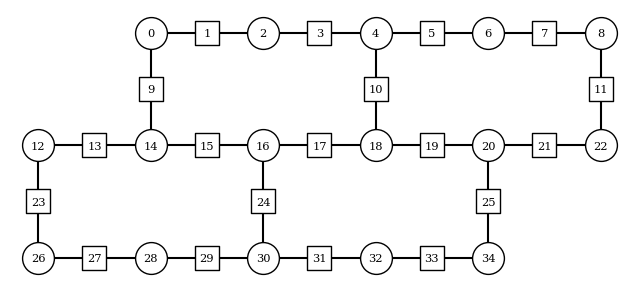

In [7]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

# Simulation settings

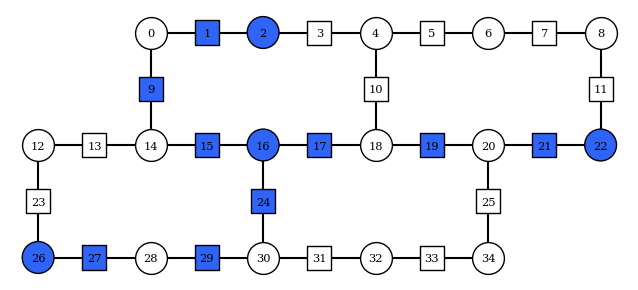

In [8]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 5
h = 2
lamb = 1

x_basis = False

fractional_gates = False

string = "3string"

final_time = 8
dt = 0.01
exp_order = 30
bond_dimension = 128

data_folderpath = "TN Data/"

string_dict = {
    (2, 2, "1string"): [4, 10, 17, 24, 30],
    (2, 2, "3string"): [1, 2, 9, 15, 19, 16, 17, 21, 22, 24, 26, 27, 29]
}

string_to_plot = string_dict[(plaquette_height, plaquette_width, string)]

lattice.plot_highlighted_qubits(string_to_plot, colors=["#2f64f7"]*len(string_to_plot), number_qubits=True)

# Load TN data

In [9]:
import numpy as np
import os

tn_data_filepath = os.path.join(data_folderpath, f"converted_data_{string}_BUG_g{h:.02f}_m{J:.02f}_{plaquette_width}x{plaquette_height}_dt{dt:.03f}_Tmax{final_time:.02f}_exp_order{exp_order}_M{bond_dimension:05d}.txt")
observables = np.loadtxt(tn_data_filepath)

In [10]:
tn_data_filepath

'TN Data/converted_data_3string_BUG_g2.00_m5.00_2x2_dt0.010_Tmax8.00_exp_order30_M00128.txt'

# Plots

# Animation

### White theme

In [7]:
from z2hex.plotting import local_obs_anim, truncate_colormap
import matplotlib.pyplot as plt

obs_steps = 1

interpolation_frames = 0
fps = 50
frame_to_title_func = lambda frame: f"$t = {frame * dt*obs_steps:.02f}$"

cmap_matter = truncate_colormap(plt.get_cmap("pink"), 0, 1)
cmap_gauge = truncate_colormap(plt.get_cmap("RdBu"), 0.1, 0.9)

cmap_range_matter = [0, 1]
cmap_range_gauge = [-1, 1]
cmap_label_matter = r"$(1 - \langle Z \rangle_{\mathrm{matter}})/2$"
cmap_label_gauge = r"$\langle Z \rangle_{\mathrm{gauge}})/2$"

matter_qb_inds = lattice.node_qbinds
observables_to_plot = observables.copy()[::obs_steps]
observables_to_plot[:, matter_qb_inds] = (1 - observables_to_plot[:, matter_qb_inds]) / 2

anim_filepath = f"z2hex_string_quench_tn_maxt_{final_time:.02f}_obssteps_{obs_steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_string_{"-".join([str(i) for i in string_to_plot])}_xbasis_{x_basis}.mp4"
local_obs_anim(observables_to_plot, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, filepath=anim_filepath)

ffmpeg version 7.1.1 Copyright (c) 2000-2025 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.6)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1.1_1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex

## Black theme

In [ ]:
from z2hex.plotting import local_obs_anim, truncate_colormap
import matplotlib.pyplot as plt

obs_steps = 1

interpolation_frames = 0
fps = 50
frame_to_title_func = lambda frame: f"$t = {frame * dt*obs_steps:.02f}$"

cmap_matter = None
cmap_gauge = None

cmap_range_matter = [0, 1]
cmap_range_gauge = [0, 1]
cmap_label_matter = r"$(1 - \langle Z \rangle)/2$"
cmap_label_gauge = r"$(1 - \langle Z \rangle)/2$"

matter_qb_inds = lattice.node_qbinds
observables_to_plot = observables.copy()[::obs_steps]
observables_to_plot = (1 - observables_to_plot) / 2

anim_filepath = f"dark_z2hex_string_quench_tn_maxt_{final_time:.02f}_obssteps_{obs_steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_string_{"-".join([str(i) for i in string_to_plot])}_xbasis_{x_basis}.mp4"
local_obs_anim(observables_to_plot, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_matter=cmap_range_matter, cmap_range_gauge=cmap_range_gauge, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, filepath=anim_filepath, dark_theme=True)

ffmpeg version 7.1.1 Copyright (c) 2000-2025 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.6)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1.1_1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex

## Qubits plots 

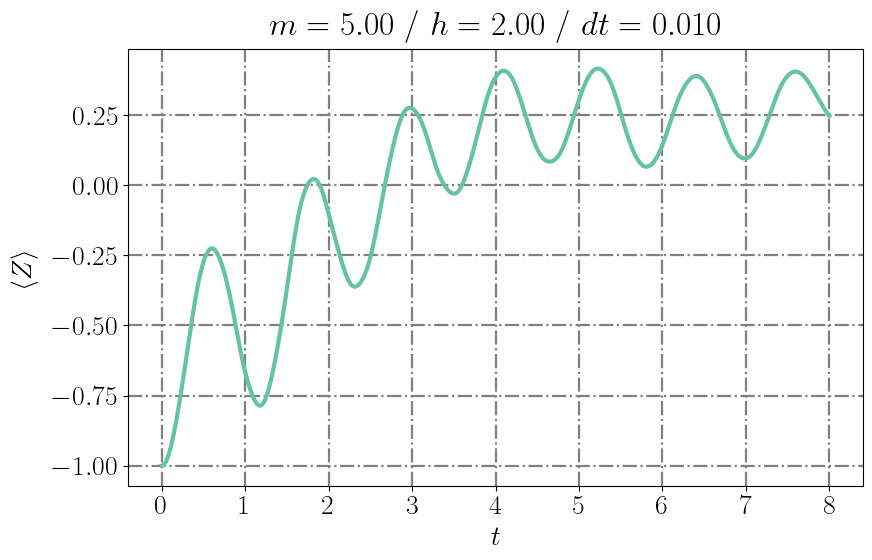

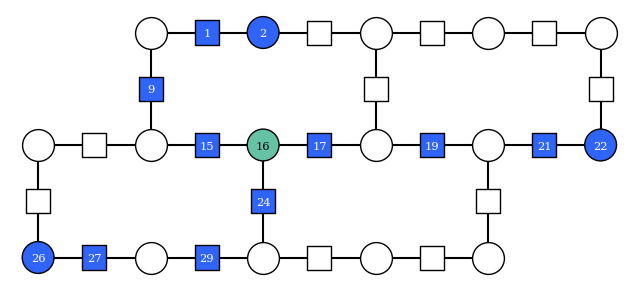

In [4]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [16]
# qubits = [14]

cmap = plt.get_cmap("Set2")
fmt = "-"
title = f"$m = {J:.02f}$ / $h = {h:.02f}$ / $dt = {dt:.03f}$"
y_lim = None # "data" for data limits, None for auto, [,] for custom
linewidth = 3
legend = False

plot_filepath = f"z2hex_quench_tn_qubits_{"-".join([str(qb) for qb in qubits])}_maxt_{final_time:.02f}_dt_{dt}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_string_{"-".join([str(i) for i in string_dict[(plaquette_height, plaquette_width, string)]])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string_dict[(plaquette_height, plaquette_width, string)]])}.pdf"

x_ticks = np.linspace(0, final_time, int(np.ceil(final_time))+1)

observables_to_plot = observables[:, qubits]

to_plot_string_qubits = list(set(string_dict[(plaquette_width, plaquette_height, string)]) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt=fmt, title=title, legend=legend, filepath=plot_filepath, data_linewidth=linewidth)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

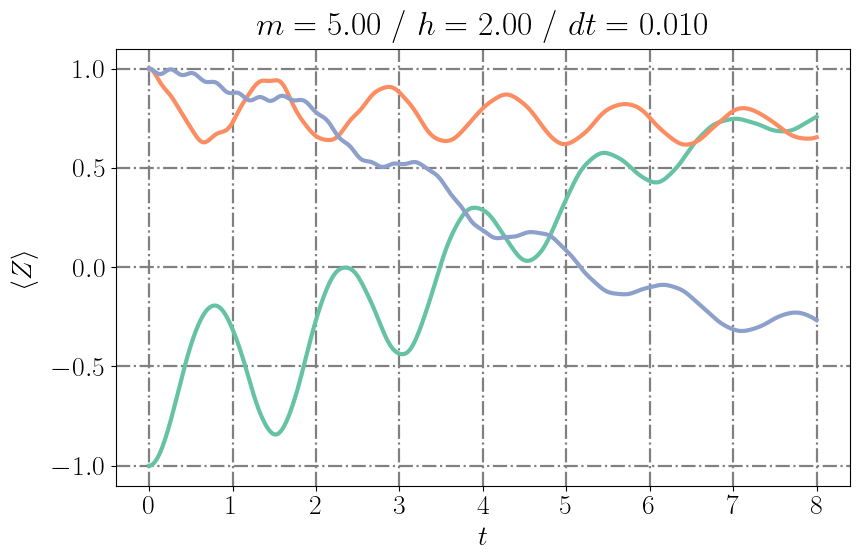

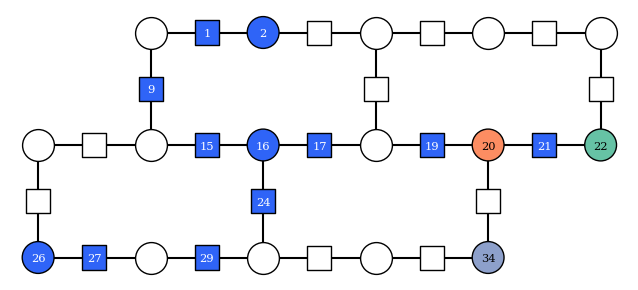

In [5]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [22, 20, 34]
# qubits = [14]

cmap = plt.get_cmap("Set2")
fmt = "-"
title = f"$m = {J:.02f}$ / $h = {h:.02f}$ / $dt = {dt:.03f}$"
y_lim = None # "data" for data limits, None for auto, [,] for custom
linewidth = 3
legend = False

plot_filepath = f"z2hex_quench_tn_qubits_{"-".join([str(qb) for qb in qubits])}_maxt_{final_time:.02f}_dt_{dt}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_string_{"-".join([str(i) for i in string_dict[(plaquette_height, plaquette_width, string)]])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string_dict[(plaquette_height, plaquette_width, string)]])}.pdf"

x_ticks = np.linspace(0, final_time, int(np.ceil(final_time))+1)

observables_to_plot = observables[:, qubits]

to_plot_string_qubits = list(set(string_dict[(plaquette_width, plaquette_height, string)]) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt=fmt, title=title, legend=legend, filepath=plot_filepath, data_linewidth=linewidth)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

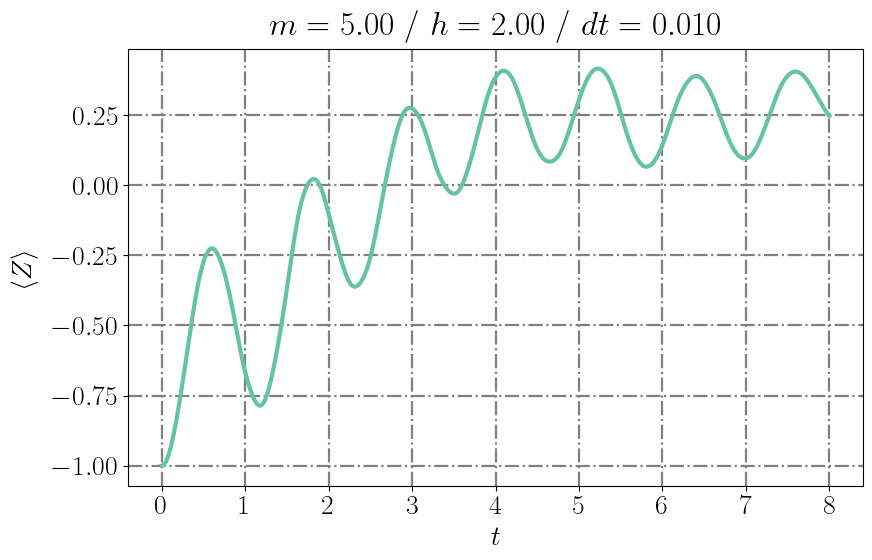

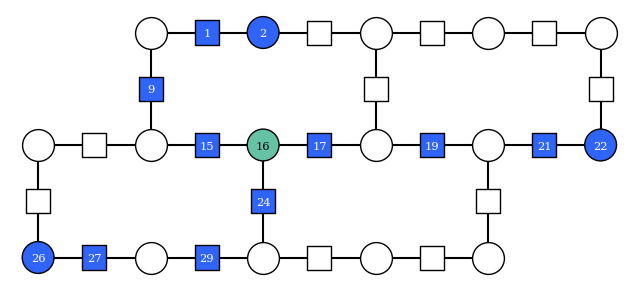

In [12]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [16]
# qubits = [14]

cmap = plt.get_cmap("Set2")
fmt = "-"
title = f"$m = {J:.02f}$ / $h = {h:.02f}$ / $dt = {dt:.03f}$"
y_lim = None # "data" for data limits, None for auto, [,] for custom
linewidth = 3
legend = False

plot_filepath = f"z2hex_quench_tn_qubits_{"-".join([str(qb) for qb in qubits])}_maxt_{final_time:.02f}_dt_{dt}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_string_{"-".join([str(i) for i in string_dict[(plaquette_height, plaquette_width, string)]])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string_dict[(plaquette_height, plaquette_width, string)]])}.pdf"

x_ticks = np.linspace(0, final_time, int(np.ceil(final_time))+1)

observables_to_plot = observables[:, qubits]

to_plot_string_qubits = list(set(string_dict[(plaquette_width, plaquette_height, string)]) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt=fmt, title=title, legend=legend, filepath=plot_filepath, data_linewidth=linewidth)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

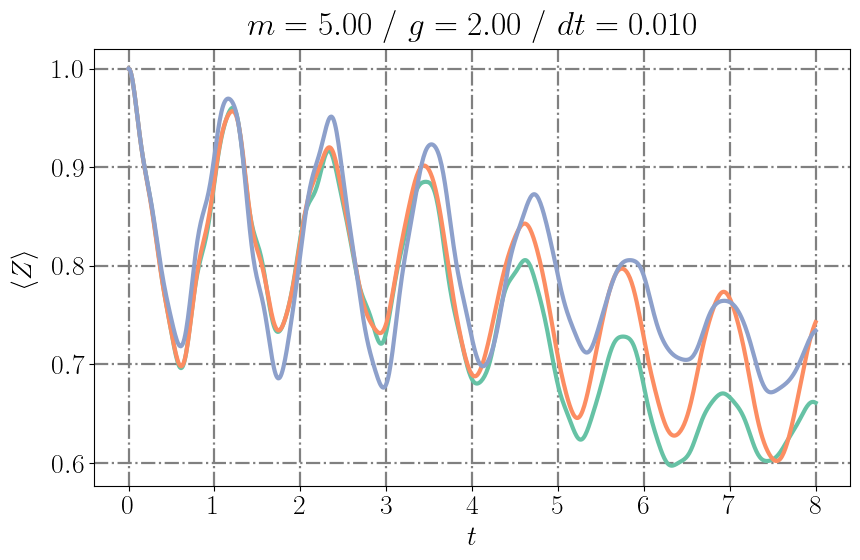

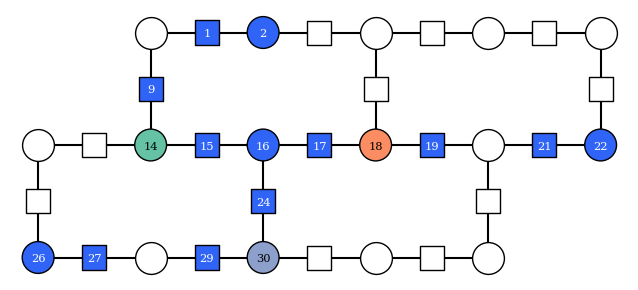

In [13]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [14, 18, 30]
# qubits = [14]

cmap = plt.get_cmap("Set2")
fmt = "-"
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
y_lim = None # "data" for data limits, None for auto, [,] for custom
linewidth = 3
legend = False

plot_filepath = f"z2hex_quench_tn_qubits_{"-".join([str(qb) for qb in qubits])}_maxt_{final_time:.02f}_dt_{dt}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_string_{"-".join([str(i) for i in string_dict[(plaquette_height, plaquette_width, string)]])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string_dict[(plaquette_height, plaquette_width, string)]])}.pdf"

x_ticks = np.linspace(0, final_time, int(np.ceil(final_time))+1)

observables_to_plot = observables[:, qubits]

to_plot_string_qubits = list(set(string_dict[(plaquette_width, plaquette_height, string)]) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt=fmt, title=title, legend=legend, filepath=plot_filepath, data_linewidth=linewidth)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

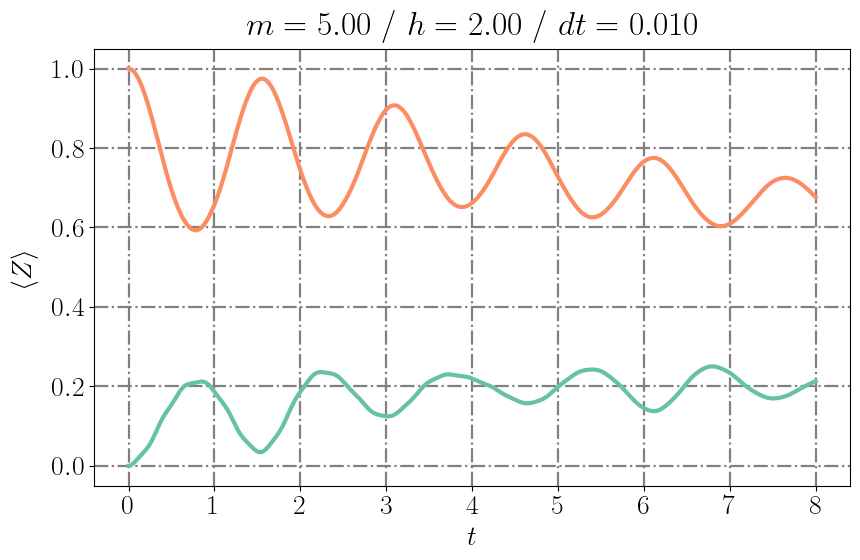

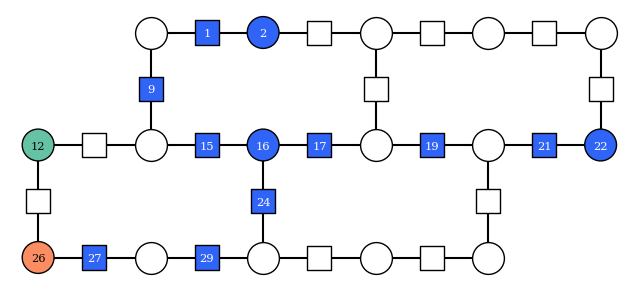

In [6]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [12, 26]
# qubits = [14]

cmap = plt.get_cmap("Set2")
fmt = "-"
title = f"$m = {J:.02f}$ / $h = {h:.02f}$ / $dt = {dt:.03f}$"
y_lim = None # "data" for data limits, None for auto, [,] for custom
linewidth = 3
legend = False

plot_filepath = f"z2hex_quench_tn_qubits_{"-".join([str(qb) for qb in qubits])}_maxt_{final_time:.02f}_dt_{dt}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_string_{"-".join([str(i) for i in string_dict[(plaquette_height, plaquette_width, string)]])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string_dict[(plaquette_height, plaquette_width, string)]])}.pdf"

x_ticks = np.linspace(0, final_time, int(np.ceil(final_time))+1)

observables_to_plot = (1 - observables[:, qubits]) / 2

to_plot_string_qubits = list(set(string_dict[(plaquette_width, plaquette_height, string)]) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt=fmt, title=title, legend=legend, filepath=plot_filepath, data_linewidth=linewidth)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

## Contour plots

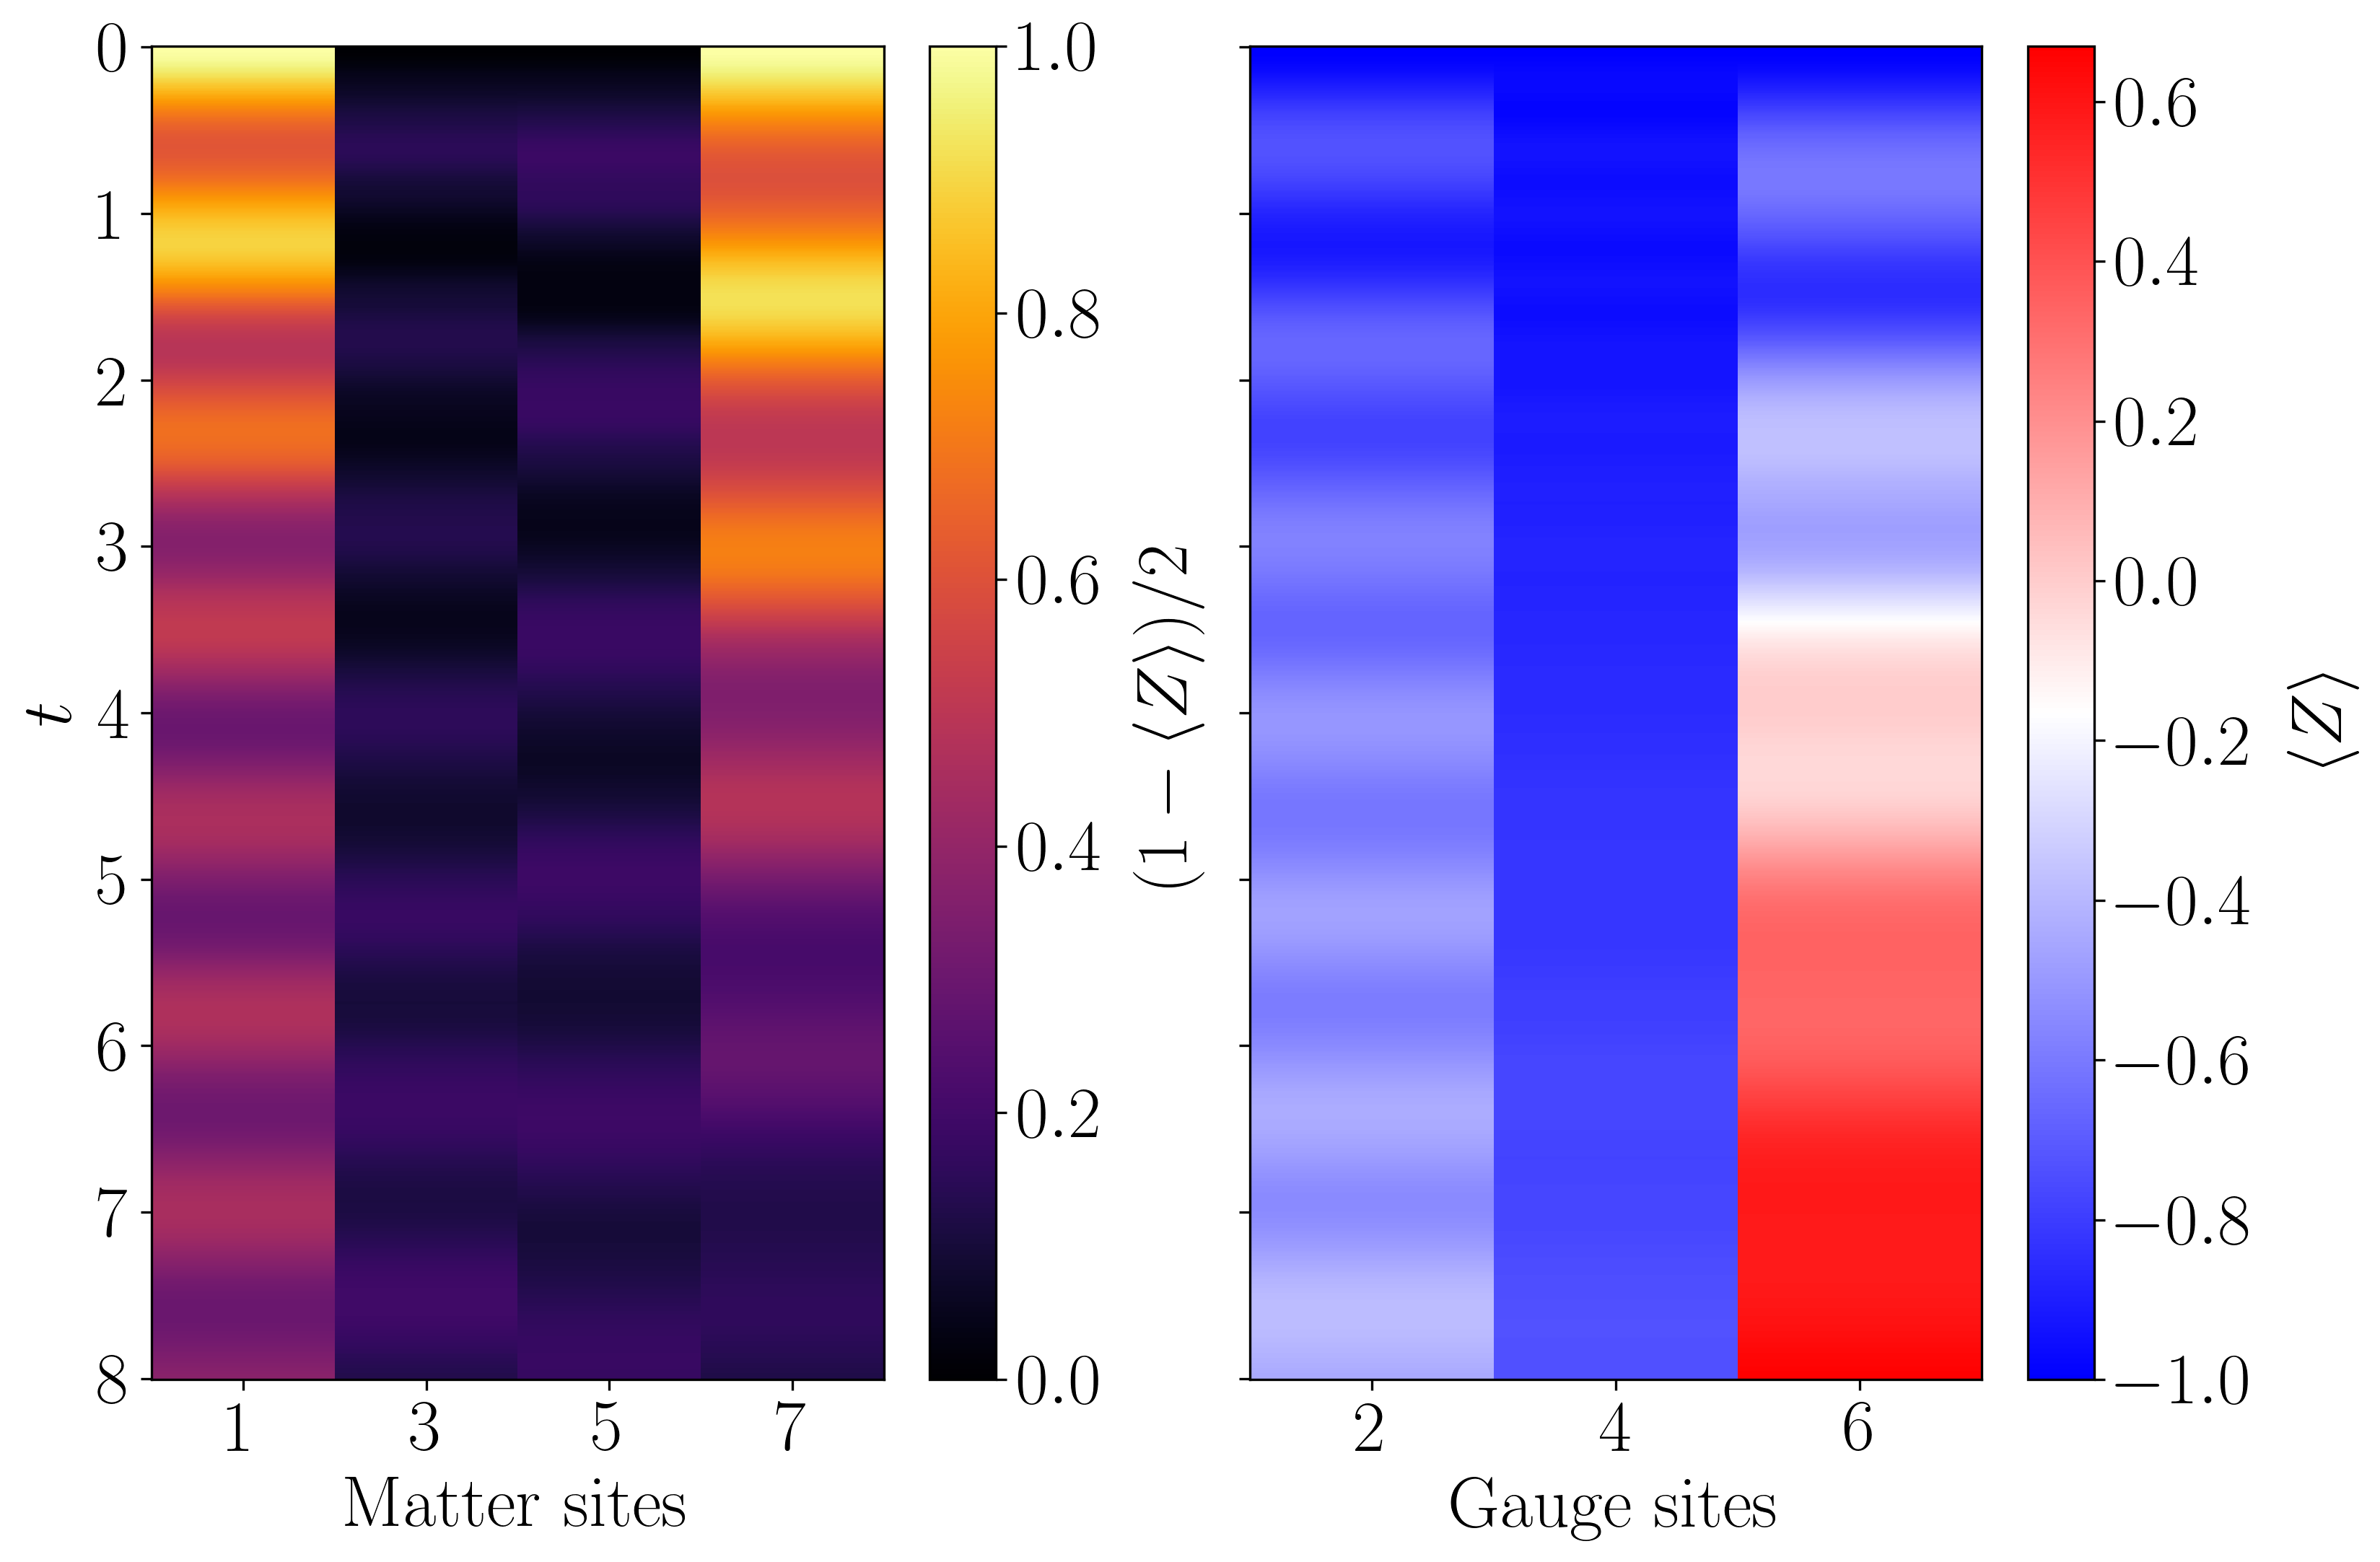

In [8]:
from z2chain.plotting import x_t_separated_plot

qubits = [16, 17, 18, 19, 20, 21, 22]

observables_to_plot = observables[:, qubits]
y_ticks = np.linspace(0, final_time, 9)
ylabel = r"$t$"

x_t_separated_plot(observables_to_plot, y_ticks=y_ticks, ylabel=ylabel)

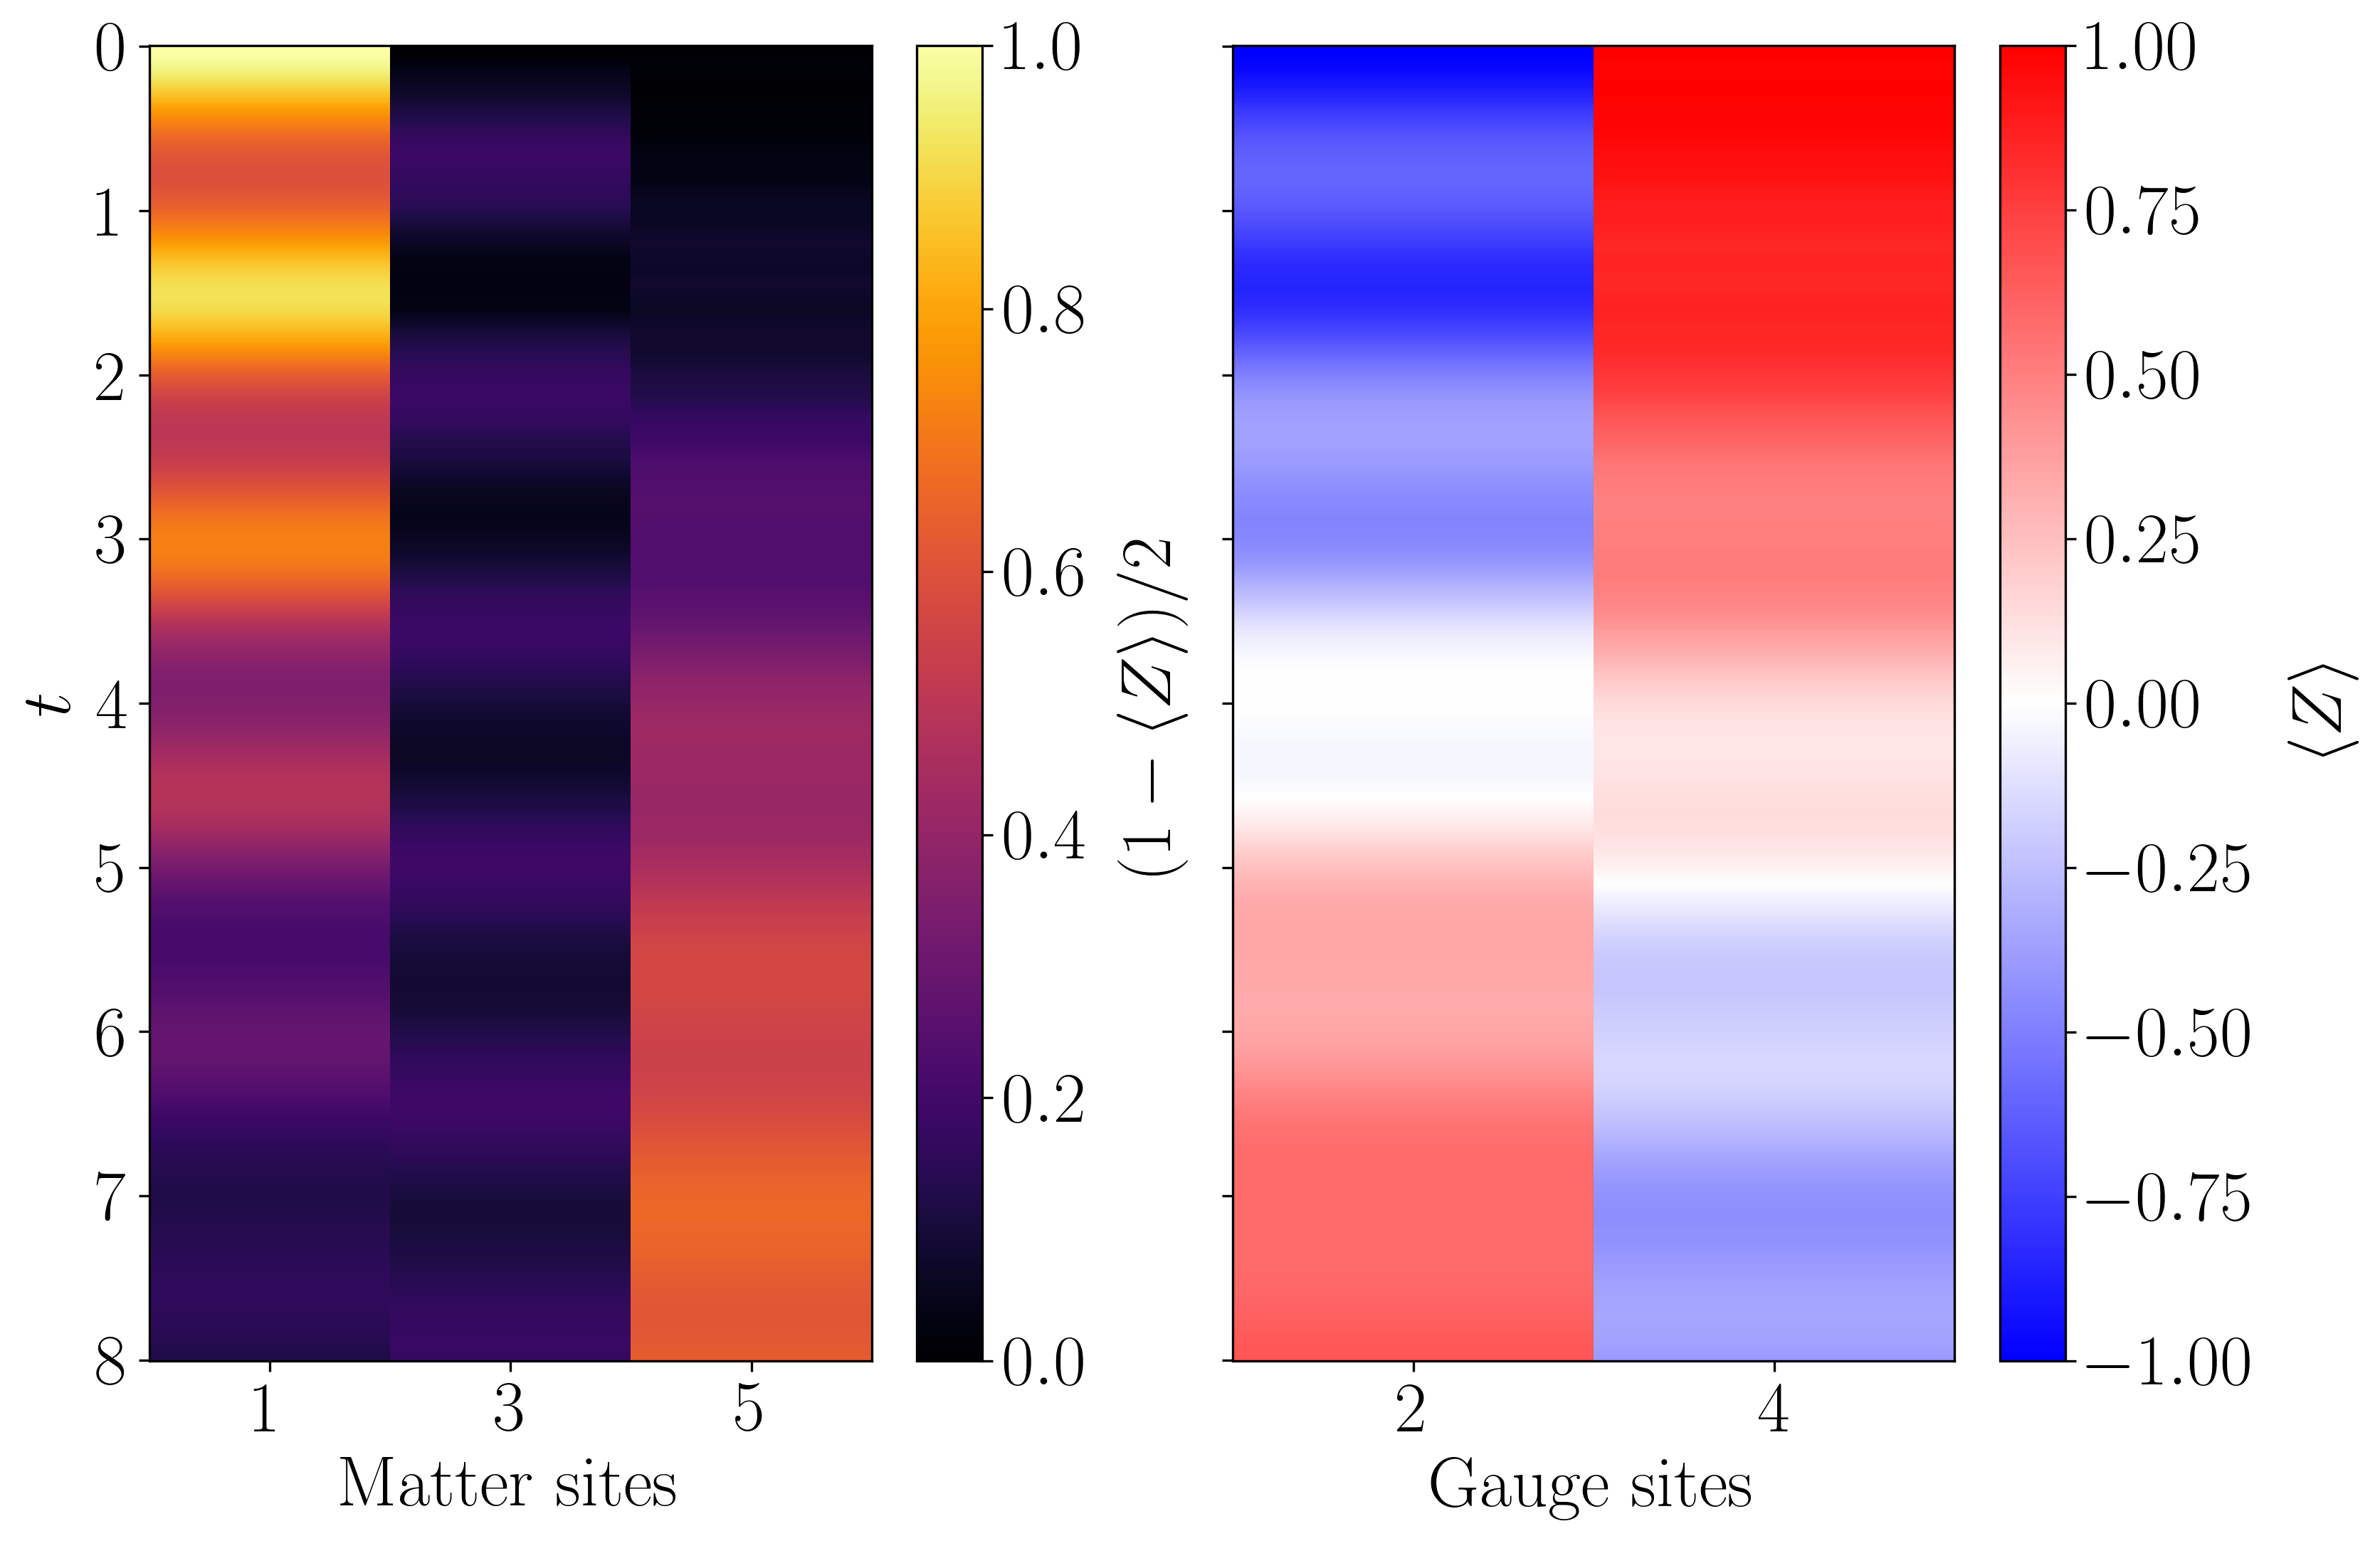

In [10]:
from z2chain.plotting import x_t_separated_plot

qubits = [22, 21, 20, 25, 34]

observables_to_plot = observables[:, qubits]
y_ticks = np.linspace(0, final_time, 9)
ylabel = r"$t$"

x_t_separated_plot(observables_to_plot, y_ticks=y_ticks, ylabel=ylabel)

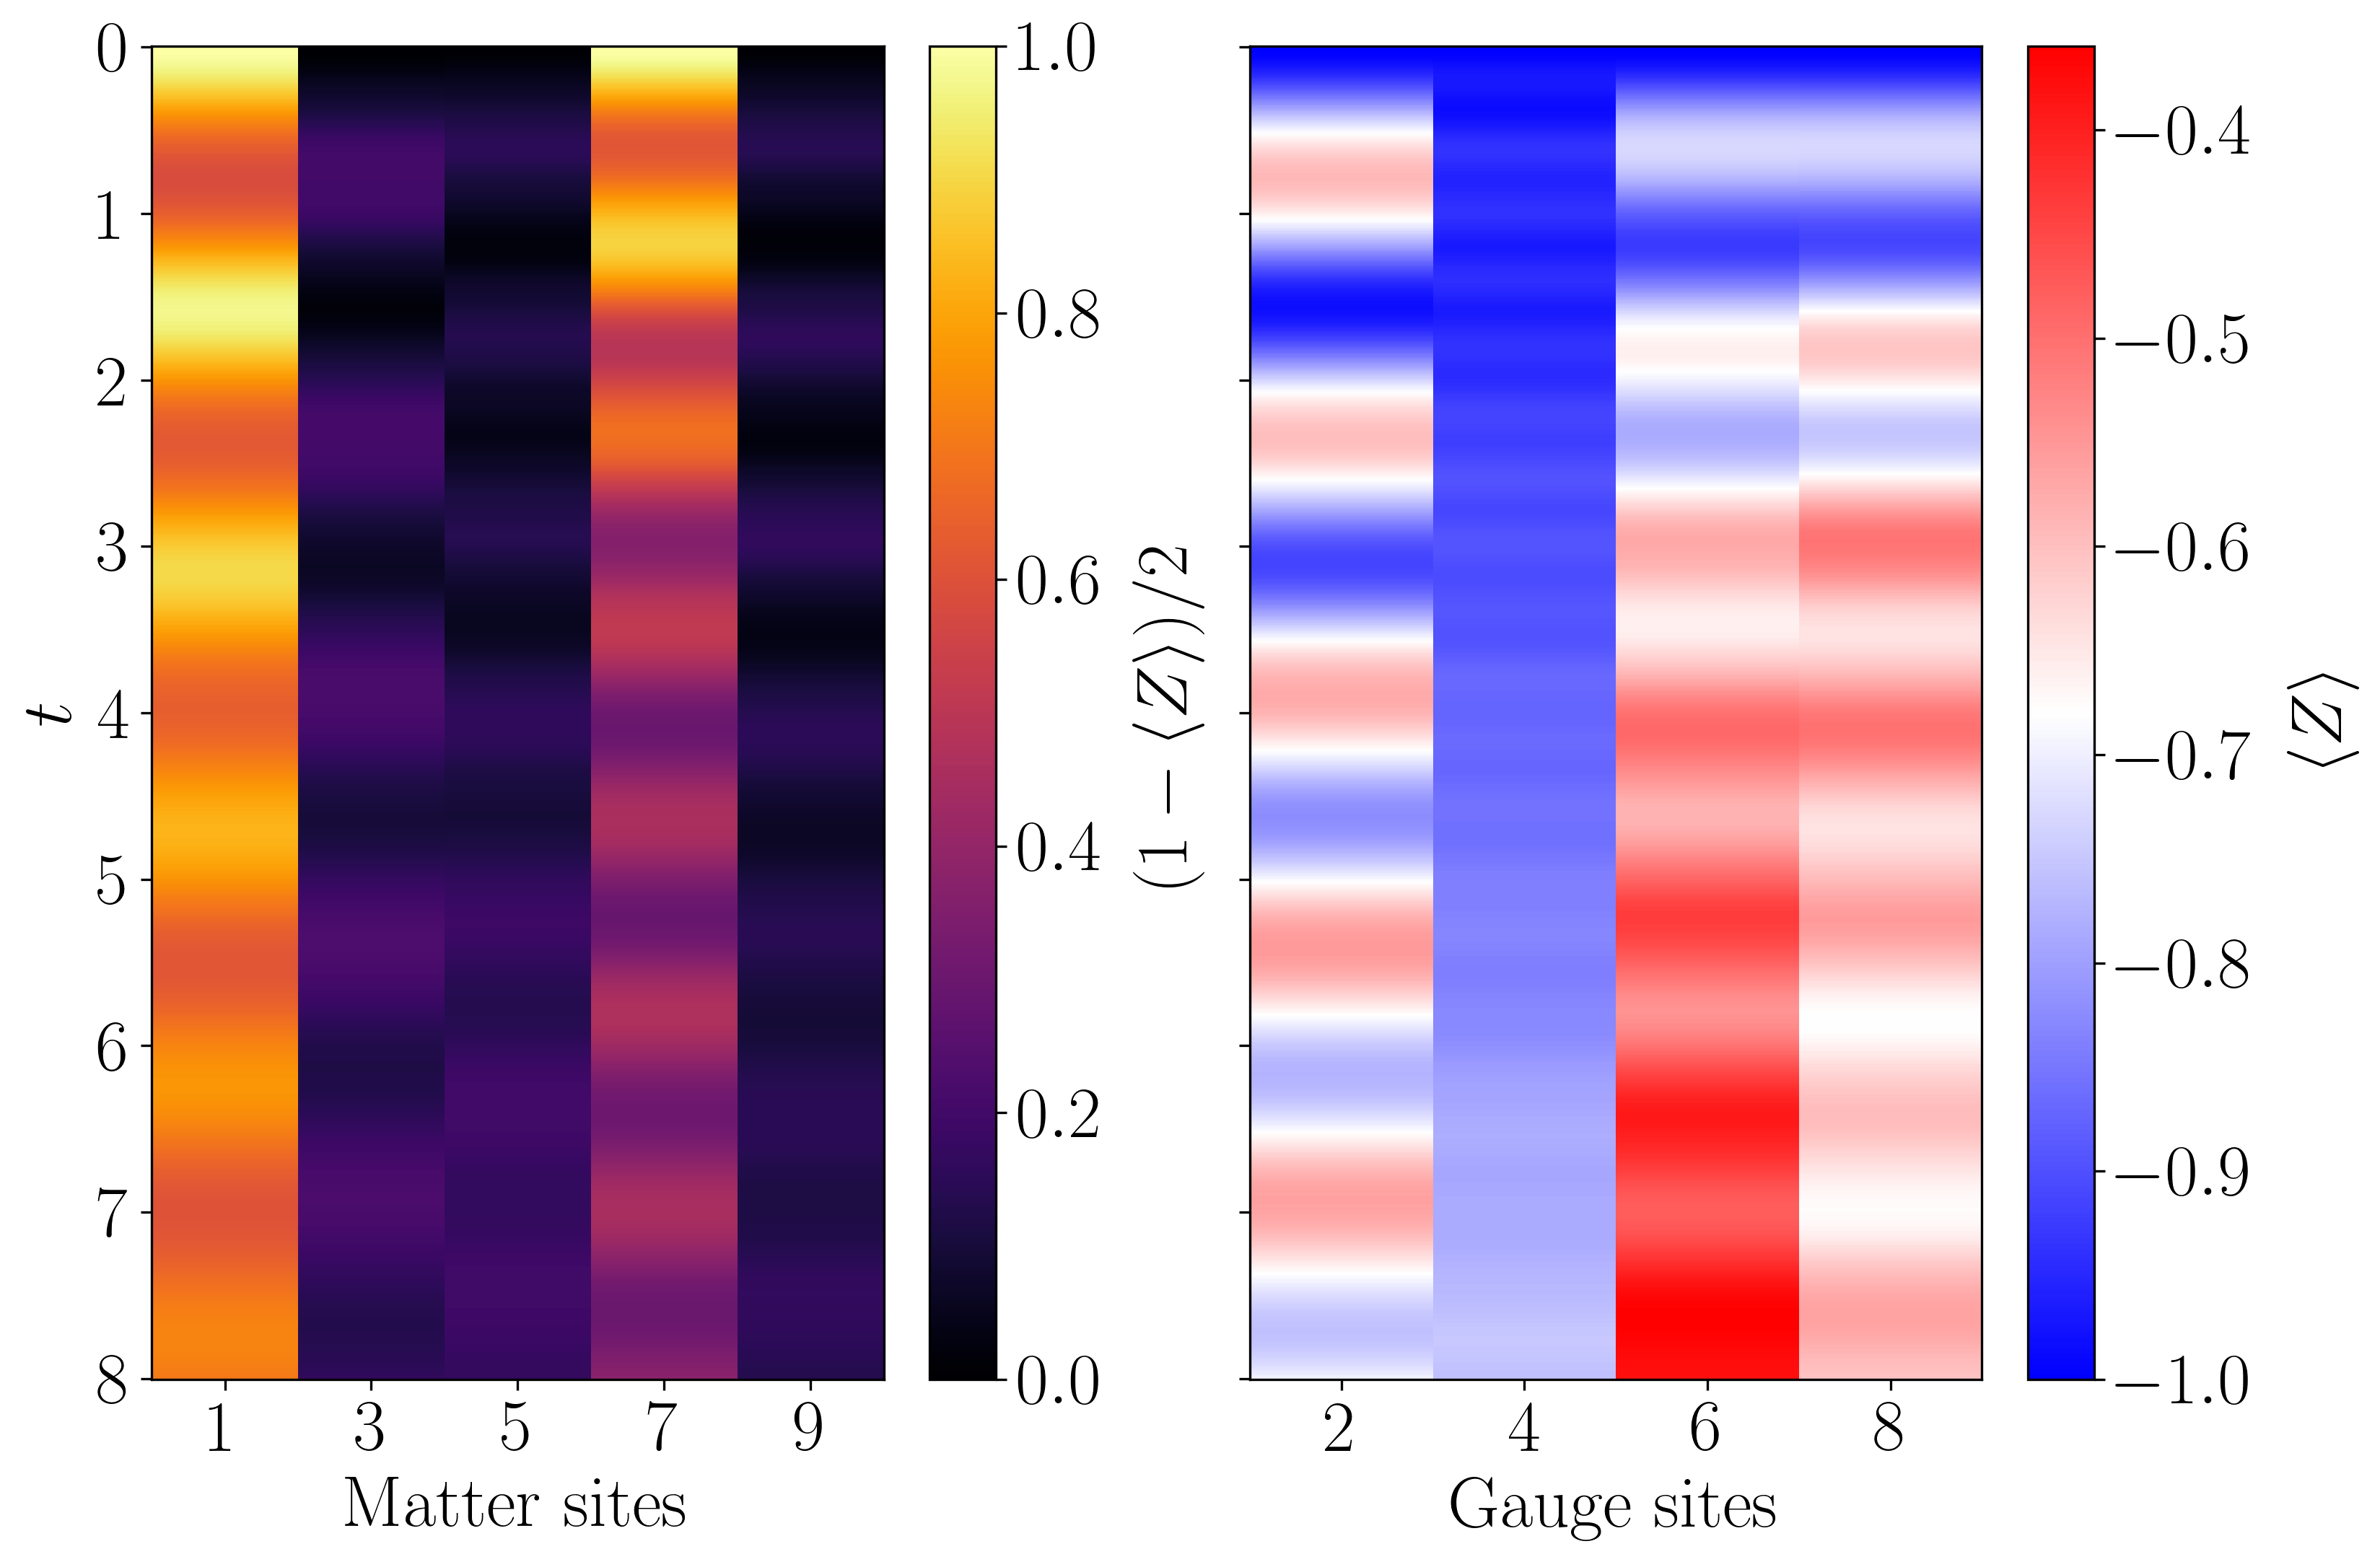

In [11]:
from z2chain.plotting import x_t_separated_plot

qubits = [2, 1, 0, 9, 14, 15, 16, 24, 30]

observables_to_plot = observables[:, qubits]
y_ticks = np.linspace(0, final_time, 9)
ylabel = r"$t$"

x_t_separated_plot(observables_to_plot, y_ticks=y_ticks, ylabel=ylabel)